In [62]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

DATA_PATH = Path('..') / 'opsd-time_series-2020-10-06'

In [63]:
raw_load = pd.read_csv(DATA_PATH / 'time_series_60min_singleindex.csv')
raw_weather = pd.read_csv(DATA_PATH / 'weather_data.csv')

print(raw_weather.head())

          utc_timestamp  AT_temperature  AT_radiation_direct_horizontal  \
0  1980-01-01T00:00:00Z          -3.640                             0.0   
1  1980-01-01T01:00:00Z          -3.803                             0.0   
2  1980-01-01T02:00:00Z          -3.969                             0.0   
3  1980-01-01T03:00:00Z          -4.076                             0.0   
4  1980-01-01T04:00:00Z          -4.248                             0.0   

   AT_radiation_diffuse_horizontal  BE_temperature  \
0                              0.0          -0.720   
1                              0.0          -1.165   
2                              0.0          -1.434   
3                              0.0          -1.843   
4                              0.0          -2.094   

   BE_radiation_direct_horizontal  BE_radiation_diffuse_horizontal  \
0                             0.0                              0.0   
1                             0.0                              0.0   
2             

In [64]:
COLUMNS_TO_KEEP_LOAD = ["cet_cest_timestamp",
                   "CZ_load_actual_entsoe_transparency",
                   "CZ_solar_generation_actual",
                   "CZ_wind_onshore_generation_actual"]
COLUMNS_TO_KEEP_WEATHER =["utc_timestamp",
                          "CZ_temperature",
                          "CZ_radiation_direct_horizontal",
                          "CZ_radiation_diffuse_horizontal"]

czech_load = raw_load[COLUMNS_TO_KEEP_LOAD]
czech_weather = raw_weather[COLUMNS_TO_KEEP_WEATHER]

In [65]:
czech_load.index = pd.to_datetime(czech_load["cet_cest_timestamp"], utc = True).dt.tz_convert("Europe/Prague")
czech_weather.index = pd.to_datetime(czech_weather["utc_timestamp"], utc = True).dt.tz_convert("Europe/Prague")

czech_load = czech_load.drop(columns = ["cet_cest_timestamp"])
czech_weather = czech_weather.drop(columns = ["utc_timestamp"])

In [66]:
time_check_load = czech_load.index.to_series().diff()
print(time_check_load.dropna().value_counts(), "\nshape:", czech_load.shape)

time_check_weather = czech_weather.index.to_series().diff()
print(time_check_weather.dropna().value_counts(), "\nshape:", czech_weather.shape)


cet_cest_timestamp
0 days 01:00:00    50400
Name: count, dtype: int64 
shape: (50401, 3)
utc_timestamp
0 days 01:00:00    350639
Name: count, dtype: int64 
shape: (350640, 3)


In [67]:
czech_df = czech_load.join(czech_weather)
czech_df.head(5)

,CZ_load_actual_entsoe_transparency,CZ_solar_generation_actual,CZ_wind_onshore_generation_actual,CZ_temperature,CZ_radiation_direct_horizontal,CZ_radiation_diffuse_horizontal
cet_cest_timestamp,,,,,,
2015-01-01 00:00:00+01:00,NaN,NaN,NaN,-2.604,0.0,0.0
2015-01-01 01:00:00+01:00,NaN,NaN,NaN,-2.372,0.0,0.0
2015-01-01 02:00:00+01:00,5957.57,NaN,38.48,-2.126,0.0,0.0
2015-01-01 03:00:00+01:00,5878.87,NaN,56.20,-1.839,0.0,0.0
2015-01-01 04:00:00+01:00,5827.80,NaN,71.21,-1.521,0.0,0.0


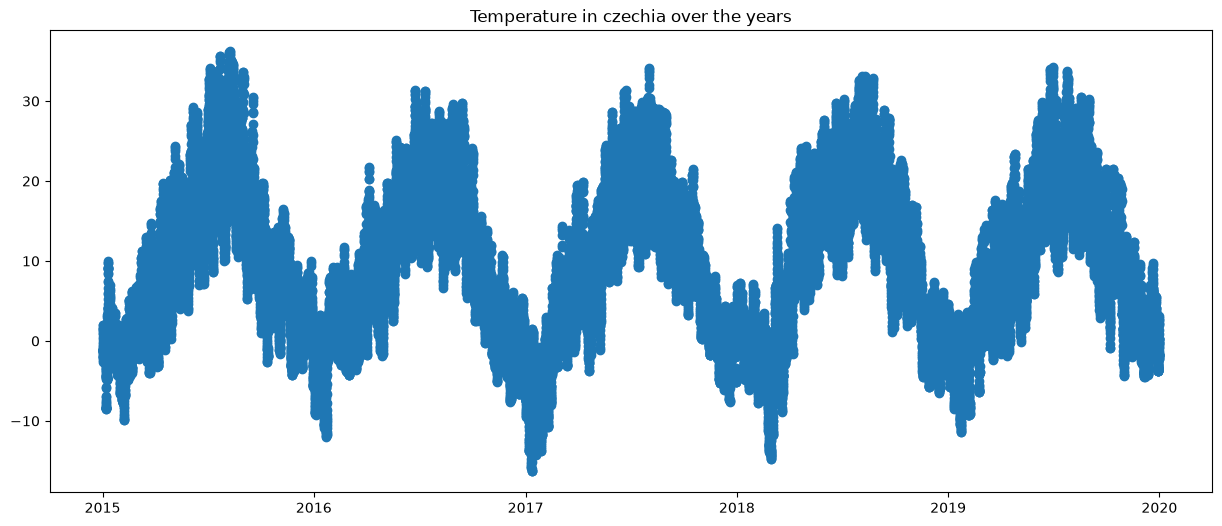

In [68]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.scatter(czech_df.index, czech_df['CZ_temperature'])
ax.set_title('Temperature in czechia over the years')

plt.show()

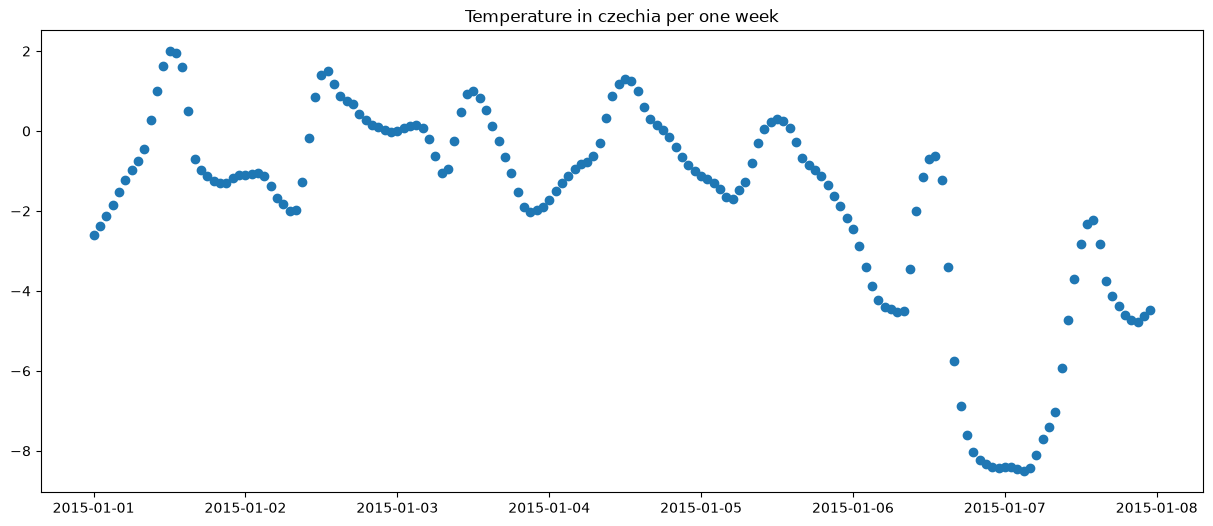

In [69]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.scatter(czech_df.index[:168], czech_df['CZ_temperature'][:168])
ax.set_title('Temperature in czechia per one week')

plt.show()

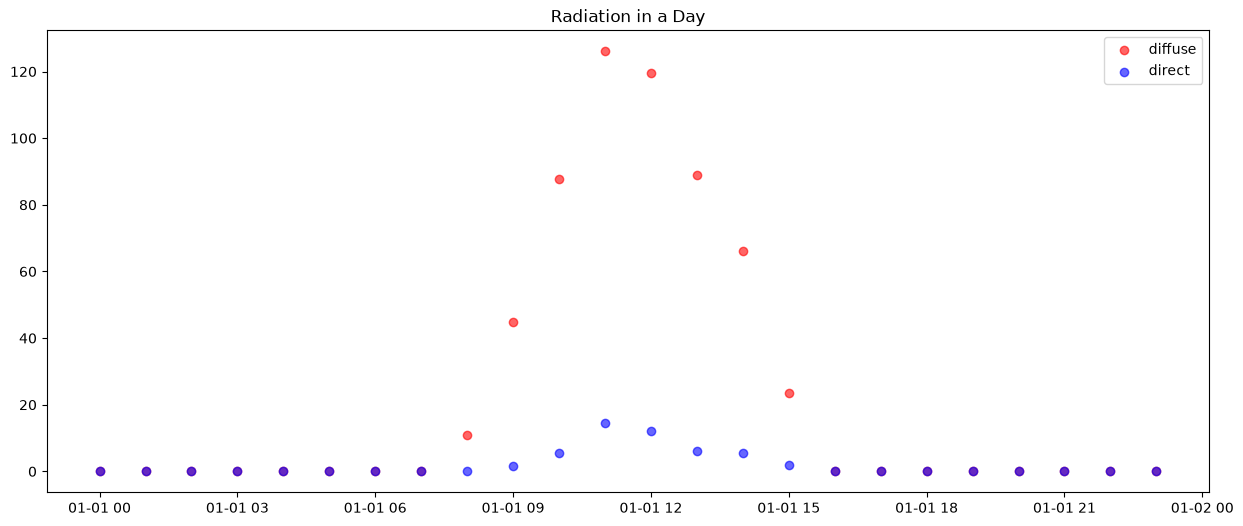

In [70]:
fig, ax = plt.subplots(figsize = (15, 6))

ax.scatter(czech_df.index[:24], czech_df['CZ_radiation_diffuse_horizontal'][:24], color = 'red', label = 'diffuse', alpha=0.6)
ax.scatter(czech_df.index[:24], czech_df['CZ_radiation_direct_horizontal'][:24], color = 'blue', label = 'direct', alpha=0.6)
ax.set_title("Radiation in a Day")
ax.legend()

plt.show()

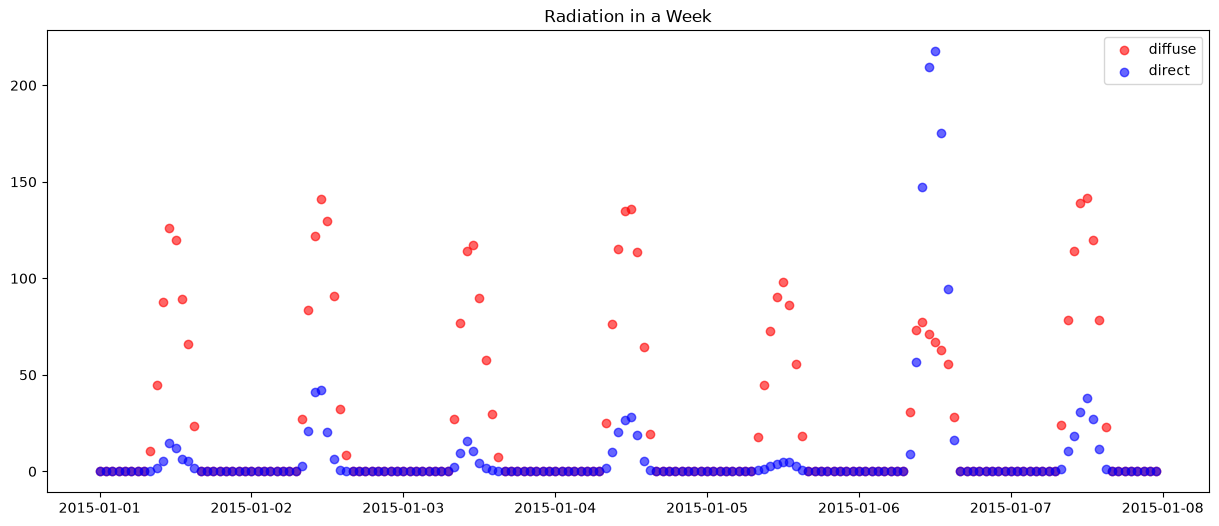

In [71]:
fig, ax = plt.subplots(figsize = (15, 6))

ax.scatter(czech_df.index[:168], czech_df['CZ_radiation_diffuse_horizontal'][:168], color='red', label = 'diffuse', alpha=0.6)
ax.scatter(czech_df.index[:168], czech_df['CZ_radiation_direct_horizontal'][:168], color='blue', label = 'direct', alpha=0.6)
ax.legend()
ax.set_title("Radiation in a Week")

plt.show()

In [72]:
czech_df.to_csv(Path("..") / "opsd-time_series-2020-10-06" / "load_with_weather.csv")